In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Profit Made: 6487847.07


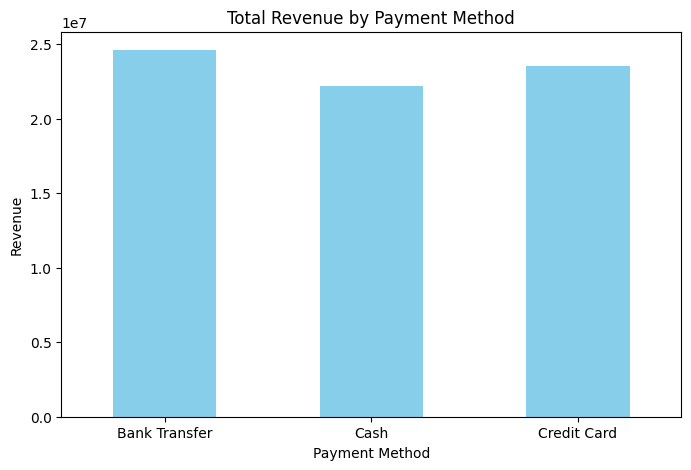

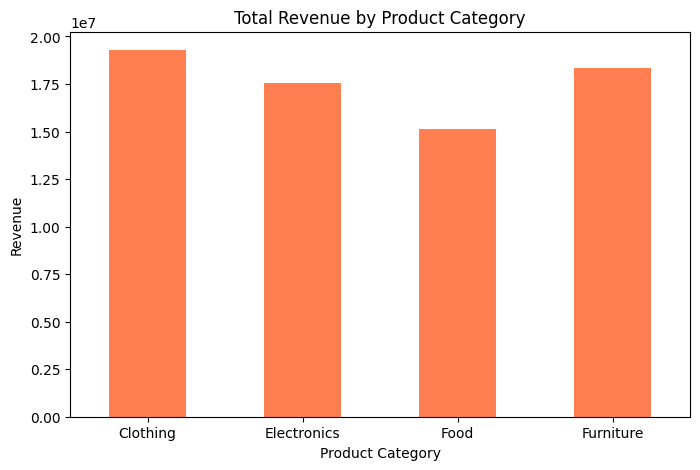

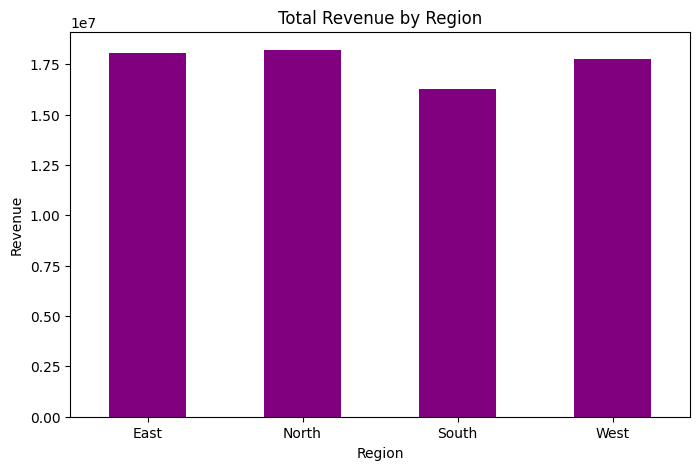

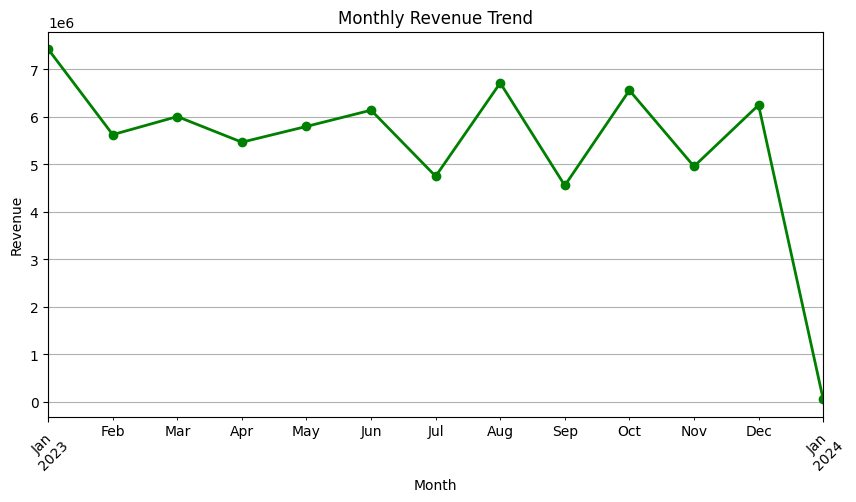

In [49]:
################################################################## Data Preparation ##################################################################

# Import the data
sales = pd.read_csv("git_sales_data.csv")
sales.head(2)

# 1.To know the row and column
sales.shape

# 2. To see missing values
sales.isnull().sum()

# 3. To see  the missing columns
sales[sales.isnull().any(axis=1)]

# 4. To see duplicated values
sales[sales.duplicated(keep="first")]

                                            ############# Business Analysis #############

# 1. Total number of product ordered = 100 orders
sales['Product_ID'].nunique()

# 2. Total number of Sales_Rep = 5 persons
sales['Sales_Rep'].nunique()

# 3. Names of the regions = 4 regions ['North', 'West', 'South', 'East']
sales['Region'].unique()

# 4. Total Revenue Made = ($70329940.71)
revenue = sales['Unit_Price'] * sales['Quantity_Sold']
revenue.sum()

# 5. Total Cost Incurred ($63842093.64)
cost = sales['Unit_Cost'] * sales['Quantity_Sold']
cost.sum()

# 6. To calculate the profit made = ($6487847.07)
Cost = sales['Unit_Cost'] * sales['Quantity_Sold']
Price = sales['Unit_Price'] * sales['Quantity_Sold']
profit = Price - Cost
profit.sum()
print("Profit Made:", profit.sum())

# 7. Total Qauntity Sold = 25355 Units
sales['Quantity_Sold'].sum()

# 8. Product Categories = 4 Categories ['Furniture', 'Food', 'Clothing', 'Electronics']
sales['Product_Category'].unique()

# 9. Customer Type per Product ID
sales.groupby(['Customer_Type']) ['Product_ID'].count()

# 10. Payment Method per Revenue
revenue.groupby(sales['Payment_Method']).sum()

# 11. Payment Method per Revenue
revenue.groupby(sales['Sales_Channel']).sum()


                                            #############  Revenue Per Month, Year ############# 

#12. Revenue per Month
revenue.groupby(pd.to_datetime(sales['Sale_Date']).dt.to_period('M')).sum()

#13. Revenue per Year
revenue.groupby(pd.to_datetime(sales['Sale_Date']).dt.to_period('Y')).sum()

#13. Revenue per WeekDay
revenue.groupby(pd.to_datetime(sales['Sale_Date']).dt.day_name()).sum()

                                            ############# Region Per Revenue #############
revenue.groupby([sales['Sales_Rep'], sales['Region']]).sum()
                                          
                                            ############# Visualization #############
# 1. Revenue by Payment Method (Bar Chart)
plt.figure(figsize=(8, 5))
revenue.groupby(sales['Payment_Method']).sum().plot(kind='bar', color='skyblue')
plt.title('Total Revenue by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Revenue')
plt.xticks(rotation=0)
plt.show()

# 2. Revenue by Product Category (Bar Chart)
plt.figure(figsize=(8, 5))
revenue.groupby(sales['Product_Category']).sum().plot(kind='bar', color='coral')
plt.title('Total Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Revenue')
plt.xticks(rotation=0)
plt.show()

# 3. Revenue by Region (Bar Chart)
plt.figure(figsize=(8, 5))
revenue.groupby(sales['Region']).sum().plot(kind='bar', color='purple')
plt.title('Total Revenue by Region')
plt.xlabel('Region')
plt.ylabel('Revenue')
plt.xticks(rotation=0)
plt.show()

# 4. Monthly Revenue Trend
plt.figure(figsize=(10, 5))
revenue.groupby(pd.to_datetime(sales['Sale_Date']).dt.to_period('M')).sum().plot(
    kind='line', marker='o', color='green', linewidth=2)
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True)
plt.xticks(rotation=45)
plt.show()